<a href="https://colab.research.google.com/github/Shamit-butterchicken/GenAI_with_LLM/blob/main/Energy_Based_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import random
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import activations, callbacks, datasets, layers, metrics, models, optimizers

# Confirm GPU availability
print("GPU Available:", tf.config.list_physical_devices('GPU'))

# Hyperparameters
IMAGE_SIZE = 32
CHANNELS = 1
STEP_SIZE = 10
STEPS = 60
NOISE = 0.005
ALPHA = 0.1
GRADIENT_CLIP = 0.03
BATCH_SIZE = 128
BUFFER_SIZE = 8192
LEARNING_RATE = 0.0001
EPOCHS = 120  # Set to 120 epochs as per assignment instructions

GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Load standard MNIST dataset
(x_train, _), (x_test, _) = datasets.mnist.load_data()

def preprocess(imgs):
    """Normalize to [-1, 1] and pad 28x28 images to 32x32."""
    imgs = (imgs.astype("float32") - 127.5) / 127.5
    imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=-1.0)
    imgs = np.expand_dims(imgs, -1)
    return imgs

x_train = preprocess(x_train)
x_test = preprocess(x_test)

train_dataset = tf.data.Dataset.from_tensor_slices(x_train).batch(BATCH_SIZE)
test_dataset = tf.data.Dataset.from_tensor_slices(x_test).batch(BATCH_SIZE)
print("Processed MNIST Shape:", x_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Processed MNIST Shape: (60000, 32, 32, 1)


In [3]:
ebm_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
x = layers.Conv2D(16, kernel_size=5, strides=2, padding="same", activation=activations.swish)(ebm_input)
x = layers.Conv2D(32, kernel_size=3, strides=2, padding="same", activation=activations.swish)(x)
x = layers.Conv2D(64, kernel_size=3, strides=2, padding="same", activation=activations.swish)(x)
x = layers.Conv2D(64, kernel_size=3, strides=2, padding="same", activation=activations.swish)(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation=activations.swish)(x)
ebm_output = layers.Dense(1)(x)

energy_model = models.Model(ebm_input, ebm_output, name="Energy_Function")
energy_model.summary()

Model: "Energy_Function"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 16)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 2, 2, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,993 (300.75 KB)

 Trainable params: 76,993 (300.75 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
def generate_samples(model, inp_imgs, steps, step_size, noise, return_img_per_step=False):
    imgs_per_step = []
    for _ in range(steps):
        inp_imgs += tf.random.normal(inp_imgs.shape, mean=0, stddev=noise)
        inp_imgs = tf.clip_by_value(inp_imgs, -1.0, 1.0)

        with tf.GradientTape() as tape:
            tape.watch(inp_imgs)
            out_score = model(inp_imgs)
        grads = tape.gradient(out_score, inp_imgs)
        grads = tf.clip_by_value(grads, -GRADIENT_CLIP, GRADIENT_CLIP)

        inp_imgs += step_size * grads
        inp_imgs = tf.clip_by_value(inp_imgs, -1.0, 1.0)

        if return_img_per_step:
            imgs_per_step.append(inp_imgs)

    if return_img_per_step:
        return tf.stack(imgs_per_step, axis=0)
    return inp_imgs

class Buffer:
    def __init__(self, model):
        self.model = model
        self.examples = [
            tf.random.uniform(shape=(1, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
            for _ in range(BATCH_SIZE)
        ]

    def sample_new_exmps(self, steps, step_size, noise):
        n_new = np.random.binomial(BATCH_SIZE, 0.05)
        rand_imgs = tf.random.uniform((n_new, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
        old_imgs = tf.concat(
            random.choices(self.examples, k=BATCH_SIZE - n_new), axis=0
        )
        inp_imgs = tf.concat([rand_imgs, old_imgs], axis=0)
        inp_imgs = generate_samples(
            self.model, inp_imgs, steps=steps, step_size=step_size, noise=noise
        )
        self.examples = tf.split(inp_imgs, BATCH_SIZE, axis=0) + self.examples
        self.examples = self.examples[:BUFFER_SIZE]
        return inp_imgs

In [7]:
class EBM(models.Model):
    def __init__(self, model):
        super(EBM, self).__init__()
        self.model = model
        self.buffer = Buffer(self.model)
        self.alpha = ALPHA
        self.loss_metric = metrics.Mean(name="loss")
        self.reg_loss_metric = metrics.Mean(name="reg")
        self.cdiv_loss_metric = metrics.Mean(name="cdiv")
        self.real_out_metric = metrics.Mean(name="real")
        self.fake_out_metric = metrics.Mean(name="fake")

    @property
    def metrics(self):
        return [
            self.loss_metric,
            self.reg_loss_metric,
            self.cdiv_loss_metric,
            self.real_out_metric,
            self.fake_out_metric,
        ]

    # Added call method required by Keras 3 for validation
    def call(self, imgs):
        return self.model(imgs)

    def train_step(self, real_imgs):
        real_imgs += tf.random.normal(
            shape=tf.shape(real_imgs), mean=0, stddev=NOISE
        )
        real_imgs = tf.clip_by_value(real_imgs, -1.0, 1.0)
        fake_imgs = self.buffer.sample_new_exmps(
            steps=STEPS, step_size=STEP_SIZE, noise=NOISE
        )
        inp_imgs = tf.concat([real_imgs, fake_imgs], axis=0)
        with tf.GradientTape() as training_tape:
            real_out, fake_out = tf.split(self.model(inp_imgs), 2, axis=0)
            cdiv_loss = tf.reduce_mean(fake_out, axis=0) - tf.reduce_mean(
                real_out, axis=0
            )
            reg_loss = self.alpha * tf.reduce_mean(
                real_out**2 + fake_out**2, axis=0
            )
            loss = cdiv_loss + reg_loss
        grads = training_tape.gradient(loss, self.model.trainable_variables)
        self.optimizer.apply_gradients(
            zip(grads, self.model.trainable_variables)
        )
        self.loss_metric.update_state(loss)
        self.reg_loss_metric.update_state(reg_loss)
        self.cdiv_loss_metric.update_state(cdiv_loss)
        self.real_out_metric.update_state(tf.reduce_mean(real_out, axis=0))
        self.fake_out_metric.update_state(tf.reduce_mean(fake_out, axis=0))
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, real_imgs):
        batch_size = tf.shape(real_imgs)[0]
        fake_imgs = (
            tf.random.uniform((batch_size, IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
            * 2
            - 1
        )
        inp_imgs = tf.concat([real_imgs, fake_imgs], axis=0)
        real_out, fake_out = tf.split(self.model(inp_imgs), 2, axis=0)
        cdiv = tf.reduce_mean(fake_out, axis=0) - tf.reduce_mean(
            real_out, axis=0
        )
        self.cdiv_loss_metric.update_state(cdiv)
        self.real_out_metric.update_state(tf.reduce_mean(real_out, axis=0))
        self.fake_out_metric.update_state(tf.reduce_mean(fake_out, axis=0))
        return {m.name: m.result() for m in self.metrics[2:]}

ebm = EBM(energy_model)
ebm.compile(optimizer=optimizers.Adam(learning_rate=LEARNING_RATE), run_eagerly=True)

In [8]:
history = ebm.fit(
    train_dataset,
    shuffle=True,
    epochs=120,
    validation_data=test_dataset,
)

Epoch 1/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 764s 2s/step - cdiv: -0.0165 - fake: 0.0212 - loss: -0.0113 - real: 0.0377 - reg: 0.0052 - val_cdiv: -1.6399 - val_fake: -1.6986 - val_real: -0.0587
Epoch 2/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 766s 2s/step - cdiv: -0.0050 - fake: 0.0019 - loss: -0.0032 - real: 0.0069 - reg: 0.0018 - val_cdiv: -1.9917 - val_fake: -2.0297 - val_real: -0.0380
Epoch 3/120
 29/469 ━━━━━━━━━━━━━━━━━━━━ 11:49 2s/step - cdiv: -0.0058 - fake: 0.0050 - loss: -0.0045 - real: 0.0108 - reg: 0.0013

KeyboardInterrupt: 

In [9]:
import random
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import activations, datasets, layers, metrics, models, optimizers

# Confirm GPU
print("GPU Available:", tf.config.list_physical_devices('GPU'))

# 1. Hyperparameters
IMAGE_SIZE = 32
CHANNELS = 1
STEP_SIZE = 10
STEPS = 60
NOISE = 0.005
ALPHA = 0.1
GRADIENT_CLIP = 0.03
BATCH_SIZE = 128
BUFFER_SIZE = 8192
LEARNING_RATE = 0.0001
EPOCHS = 120

# 2. Data Preparation
(x_train, _), (x_test, _) = datasets.mnist.load_data()

def preprocess(imgs):
    imgs = (imgs.astype("float32") - 127.5) / 127.5
    imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=-1.0)
    return np.expand_dims(imgs, -1)

x_train = preprocess(x_train)
x_test = preprocess(x_test)

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)
test_dataset = (
    tf.data.Dataset.from_tensor_slices(x_test)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

# 3. Energy Function Network
ebm_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
x = layers.Conv2D(16, kernel_size=5, strides=2, padding="same", activation=activations.swish)(ebm_input)
x = layers.Conv2D(32, kernel_size=3, strides=2, padding="same", activation=activations.swish)(x)
x = layers.Conv2D(64, kernel_size=3, strides=2, padding="same", activation=activations.swish)(x)
x = layers.Conv2D(64, kernel_size=3, strides=2, padding="same", activation=activations.swish)(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation=activations.swish)(x)
ebm_output = layers.Dense(1)(x)

energy_model = models.Model(ebm_input, ebm_output, name="Energy_Function")

# 4. Graph-Compiled Langevin Sampler
@tf.function
def generate_samples(model, inp_imgs, steps, step_size, noise):
    for _ in tf.range(steps):
        inp_imgs += tf.random.normal(tf.shape(inp_imgs), mean=0.0, stddev=noise)
        inp_imgs = tf.clip_by_value(inp_imgs, -1.0, 1.0)

        with tf.GradientTape() as tape:
            tape.watch(inp_imgs)
            out_score = model(inp_imgs)
        grads = tape.gradient(out_score, inp_imgs)
        grads = tf.clip_by_value(grads, -GRADIENT_CLIP, GRADIENT_CLIP)

        inp_imgs += step_size * grads
        inp_imgs = tf.clip_by_value(inp_imgs, -1.0, 1.0)

    return inp_imgs

# 5. Replay Buffer
class Buffer:
    def __init__(self, model):
        self.model = model
        self.examples = [
            tf.random.uniform(shape=(1, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
            for _ in range(BATCH_SIZE)
        ]

    def sample_new_exmps(self, steps, step_size, noise):
        n_new = np.random.binomial(BATCH_SIZE, 0.05)
        rand_imgs = tf.random.uniform((n_new, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
        old_imgs = tf.concat(
            random.choices(self.examples, k=BATCH_SIZE - n_new), axis=0
        )
        inp_imgs = tf.concat([rand_imgs, old_imgs], axis=0)

        inp_imgs = generate_samples(
            self.model, inp_imgs, steps=steps, step_size=step_size, noise=noise
        )

        self.examples = tf.split(inp_imgs, BATCH_SIZE, axis=0) + self.examples
        self.examples = self.examples[:BUFFER_SIZE]
        return inp_imgs

# 6. Optimized EBM Model
class EBM(models.Model):
    def __init__(self, model):
        super(EBM, self).__init__()
        self.model = model
        self.buffer = Buffer(self.model)
        self.alpha = ALPHA
        self.loss_metric = metrics.Mean(name="loss")
        self.reg_loss_metric = metrics.Mean(name="reg")
        self.cdiv_loss_metric = metrics.Mean(name="cdiv")
        self.real_out_metric = metrics.Mean(name="real")
        self.fake_out_metric = metrics.Mean(name="fake")

    @property
    def metrics(self):
        return [
            self.loss_metric,
            self.reg_loss_metric,
            self.cdiv_loss_metric,
            self.real_out_metric,
            self.fake_out_metric,
        ]

    def call(self, imgs):
        return self.model(imgs)

    def train_step(self, real_imgs):
        real_imgs += tf.random.normal(
            shape=tf.shape(real_imgs), mean=0, stddev=NOISE
        )
        real_imgs = tf.clip_by_value(real_imgs, -1.0, 1.0)

        fake_imgs = self.buffer.sample_new_exmps(
            steps=STEPS, step_size=STEP_SIZE, noise=NOISE
        )

        inp_imgs = tf.concat([real_imgs, fake_imgs], axis=0)
        with tf.GradientTape() as training_tape:
            real_out, fake_out = tf.split(self.model(inp_imgs), 2, axis=0)
            cdiv_loss = tf.reduce_mean(fake_out, axis=0) - tf.reduce_mean(real_out, axis=0)
            reg_loss = self.alpha * tf.reduce_mean(real_out**2 + fake_out**2, axis=0)
            loss = cdiv_loss + reg_loss

        grads = training_tape.gradient(loss, self.model.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.model.trainable_variables))

        self.loss_metric.update_state(loss)
        self.reg_loss_metric.update_state(reg_loss)
        self.cdiv_loss_metric.update_state(cdiv_loss)
        self.real_out_metric.update_state(tf.reduce_mean(real_out, axis=0))
        self.fake_out_metric.update_state(tf.reduce_mean(fake_out, axis=0))
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, real_imgs):
        batch_size = tf.shape(real_imgs)[0]
        fake_imgs = (
            tf.random.uniform((batch_size, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
        )
        inp_imgs = tf.concat([real_imgs, fake_imgs], axis=0)
        real_out, fake_out = tf.split(self.model(inp_imgs), 2, axis=0)
        cdiv = tf.reduce_mean(fake_out, axis=0) - tf.reduce_mean(real_out, axis=0)

        self.cdiv_loss_metric.update_state(cdiv)
        self.real_out_metric.update_state(tf.reduce_mean(real_out, axis=0))
        self.fake_out_metric.update_state(tf.reduce_mean(fake_out, axis=0))
        return {m.name: m.result() for m in self.metrics[2:]}

# 7. Compile WITHOUT run_eagerly for maximum performance
ebm = EBM(energy_model)
ebm.compile(optimizer=optimizers.Adam(learning_rate=LEARNING_RATE))

# 8. Train
history = ebm.fit(
    train_dataset,
    shuffle=True,
    epochs=EPOCHS,
    validation_data=test_dataset,
)

# 9. Save & Display Final Plots
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Total Loss", color="blue")
plt.plot(history.history["cdiv"], label="CDiv Loss", color="red", linestyle="--")
plt.plot(history.history["reg"], label="Reg Loss", color="green", linestyle=":")
plt.title("EBM Training Loss Components (120 Epochs)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history["real"], label="Real Score f(x_real)", color="purple")
plt.plot(history.history["fake"], label="Fake Score f(x_fake)", color="orange")
plt.title("Real vs. Fake Scores over 120 Epochs")
plt.xlabel("Epoch")
plt.ylabel("Output Score")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("mnist_ebm_loss_curves.png", dpi=300)
plt.show()

# Sample Generation
start_imgs = tf.random.uniform(shape=(10, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
gen_imgs = generate_samples(ebm.model, start_imgs, steps=1000, step_size=STEP_SIZE, noise=NOISE)

plt.figure(figsize=(15, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(gen_imgs[i].numpy().squeeze(), cmap="gray")
    plt.axis("off")
plt.suptitle("Generated MNIST Digits (120 Epochs)")
plt.savefig("generated_digits.png", dpi=300)
plt.show()

GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Epoch 1/120


InaccessibleTensorError: <tf.Tensor 'split:59' shape=(1, 32, 32, 1) dtype=float32> is out of scope and cannot be used here. Use return values, explicit Python locals or TensorFlow collections to access it.
Please see https://www.tensorflow.org/guide/function#all_outputs_of_a_tffunction_must_be_return_values for more information.

<tf.Tensor 'split:59' shape=(1, 32, 32, 1) dtype=float32> was defined here:
    File "<frozen runpy>", line 203, in _run_module_as_main
    File "<frozen runpy>", line 88, in _run_code
    File "/usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py", line 37, in <module>
    File "/usr/local/lib/python3.13/dist-packages/traitlets/config/application.py", line 992, in launch_instance
    File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelapp.py", line 712, in start
    File "/usr/local/lib/python3.13/dist-packages/tornado/platform/asyncio.py", line 211, in start
    File "/usr/lib/python3.13/asyncio/base_events.py", line 684, in run_forever

In [10]:
import random
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import activations, datasets, layers, metrics, models, optimizers

# Check GPU
print("GPU Available:", tf.config.list_physical_devices('GPU'))

# 1. Hyperparameters
IMAGE_SIZE = 32
CHANNELS = 1
STEP_SIZE = 10
STEPS = 60
NOISE = 0.005
ALPHA = 0.1
GRADIENT_CLIP = 0.03
BATCH_SIZE = 128
BUFFER_SIZE = 8192
LEARNING_RATE = 0.0001
EPOCHS = 120

# 2. Data Preparation
(x_train, _), (x_test, _) = datasets.mnist.load_data()

def preprocess(imgs):
    imgs = (imgs.astype("float32") - 127.5) / 127.5
    imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=-1.0)
    return np.expand_dims(imgs, -1)

x_train = preprocess(x_train)
x_test = preprocess(x_test)

train_dataset = tf.data.Dataset.from_tensor_slices(x_train).batch(BATCH_SIZE)
test_dataset = tf.data.Dataset.from_tensor_slices(x_test).batch(BATCH_SIZE)

# 3. Energy Function Network
ebm_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
x = layers.Conv2D(16, kernel_size=5, strides=2, padding="same", activation=activations.swish)(ebm_input)
x = layers.Conv2D(32, kernel_size=3, strides=2, padding="same", activation=activations.swish)(x)
x = layers.Conv2D(64, kernel_size=3, strides=2, padding="same", activation=activations.swish)(x)
x = layers.Conv2D(64, kernel_size=3, strides=2, padding="same", activation=activations.swish)(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation=activations.swish)(x)
ebm_output = layers.Dense(1)(x)

energy_model = models.Model(ebm_input, ebm_output, name="Energy_Function")

# 4. Graph-Compiled Langevin Sampler
@tf.function
def generate_samples(model, inp_imgs, steps, step_size, noise):
    for _ in tf.range(steps):
        inp_imgs += tf.random.normal(tf.shape(inp_imgs), mean=0.0, stddev=noise)
        inp_imgs = tf.clip_by_value(inp_imgs, -1.0, 1.0)

        with tf.GradientTape() as tape:
            tape.watch(inp_imgs)
            out_score = model(inp_imgs)
        grads = tape.gradient(out_score, inp_imgs)
        grads = tf.clip_by_value(grads, -GRADIENT_CLIP, GRADIENT_CLIP)

        inp_imgs += step_size * grads
        inp_imgs = tf.clip_by_value(inp_imgs, -1.0, 1.0)

    return inp_imgs

# 5. Replay Buffer
class Buffer:
    def __init__(self, model):
        self.model = model
        self.examples = [
            tf.random.uniform(shape=(1, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
            for _ in range(BATCH_SIZE)
        ]

    def sample_new_exmps(self, steps, step_size, noise):
        n_new = np.random.binomial(BATCH_SIZE, 0.05)
        rand_imgs = tf.random.uniform((n_new, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
        old_imgs = tf.concat(
            random.choices(self.examples, k=BATCH_SIZE - n_new), axis=0
        )
        inp_imgs = tf.concat([rand_imgs, old_imgs], axis=0)

        inp_imgs = generate_samples(
            self.model, inp_imgs, steps=steps, step_size=step_size, noise=noise
        )

        self.examples = tf.split(inp_imgs, BATCH_SIZE, axis=0) + self.examples
        self.examples = self.examples[:BUFFER_SIZE]
        return inp_imgs

# 6. EBM Keras Model
class EBM(models.Model):
    def __init__(self, model):
        super(EBM, self).__init__()
        self.model = model
        self.buffer = Buffer(self.model)
        self.alpha = ALPHA
        self.loss_metric = metrics.Mean(name="loss")
        self.reg_loss_metric = metrics.Mean(name="reg")
        self.cdiv_loss_metric = metrics.Mean(name="cdiv")
        self.real_out_metric = metrics.Mean(name="real")
        self.fake_out_metric = metrics.Mean(name="fake")

    @property
    def metrics(self):
        return [
            self.loss_metric,
            self.reg_loss_metric,
            self.cdiv_loss_metric,
            self.real_out_metric,
            self.fake_out_metric,
        ]

    def call(self, imgs):
        return self.model(imgs)

    def train_step(self, real_imgs):
        real_imgs += tf.random.normal(
            shape=tf.shape(real_imgs), mean=0, stddev=NOISE
        )
        real_imgs = tf.clip_by_value(real_imgs, -1.0, 1.0)

        fake_imgs = self.buffer.sample_new_exmps(
            steps=STEPS, step_size=STEP_SIZE, noise=NOISE
        )

        inp_imgs = tf.concat([real_imgs, fake_imgs], axis=0)
        with tf.GradientTape() as training_tape:
            real_out, fake_out = tf.split(self.model(inp_imgs), 2, axis=0)
            cdiv_loss = tf.reduce_mean(fake_out, axis=0) - tf.reduce_mean(real_out, axis=0)
            reg_loss = self.alpha * tf.reduce_mean(real_out**2 + fake_out**2, axis=0)
            loss = cdiv_loss + reg_loss

        grads = training_tape.gradient(loss, self.model.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.model.trainable_variables))

        self.loss_metric.update_state(loss)
        self.reg_loss_metric.update_state(reg_loss)
        self.cdiv_loss_metric.update_state(cdiv_loss)
        self.real_out_metric.update_state(tf.reduce_mean(real_out, axis=0))
        self.fake_out_metric.update_state(tf.reduce_mean(fake_out, axis=0))
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, real_imgs):
        batch_size = tf.shape(real_imgs)[0]
        fake_imgs = (
            tf.random.uniform((batch_size, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
        )
        inp_imgs = tf.concat([real_imgs, fake_imgs], axis=0)
        real_out, fake_out = tf.split(self.model(inp_imgs), 2, axis=0)
        cdiv = tf.reduce_mean(fake_out, axis=0) - tf.reduce_mean(real_out, axis=0)

        self.cdiv_loss_metric.update_state(cdiv)
        self.real_out_metric.update_state(tf.reduce_mean(real_out, axis=0))
        self.fake_out_metric.update_state(tf.reduce_mean(fake_out, axis=0))
        return {m.name: m.result() for m in self.metrics[2:]}

# 7. Compile with run_eagerly=True for Buffer compatibility
ebm = EBM(energy_model)
ebm.compile(optimizer=optimizers.Adam(learning_rate=LEARNING_RATE), run_eagerly=True)

# 8. Run Training
history = ebm.fit(
    train_dataset,
    shuffle=True,
    epochs=EPOCHS,
    validation_data=test_dataset,
)

# 9. Plot Loss Curves & Show Samples
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Total Loss", color="blue")
plt.plot(history.history["cdiv"], label="CDiv Loss", color="red", linestyle="--")
plt.plot(history.history["reg"], label="Reg Loss", color="green", linestyle=":")
plt.title("EBM Loss Components (120 Epochs)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history["real"], label="Real Score f(x_real)", color="purple")
plt.plot(history.history["fake"], label="Fake Score f(x_fake)", color="orange")
plt.title("Real vs. Fake Scores over 120 Epochs")
plt.xlabel("Epoch")
plt.ylabel("Output Score")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("mnist_ebm_loss_curves.png", dpi=300)
plt.show()

# Generate and plot digits
start_imgs = tf.random.uniform(shape=(10, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
gen_imgs = generate_samples(ebm.model, start_imgs, steps=1000, step_size=STEP_SIZE, noise=NOISE)

plt.figure(figsize=(15, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(gen_imgs[i].numpy().squeeze(), cmap="gray")
    plt.axis("off")
plt.suptitle("Generated MNIST Digits (120 Epochs)")
plt.savefig("generated_digits.png", dpi=300)
plt.show()

GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Epoch 1/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 75s 159ms/step - cdiv: -0.0518 - fake: 0.1534 - loss: -0.0379 - real: 0.2053 - reg: 0.0139 - val_cdiv: -1.5005 - val_fake: -1.5435 - val_real: -0.0430
Epoch 2/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 73s 155ms/step - cdiv: -0.0041 - fake: 0.0057 - loss: -0.0022 - real: 0.0098 - reg: 0.0019 - val_cdiv: -1.6919 - val_fake: -1.7704 - val_real: -0.0785
Epoch 3/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 73s 155ms/step - cdiv: -0.0030 - fake: 0.0015 - loss: -0.0018 - real: 0.0045 - reg: 0.0012 - val_cdiv: -2.0322 - val_fake: -2.0704 - val_real: -0.0382
Epoch 4/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 72s 155ms/step - cdiv: -9.1620e-04 - fake: 0.0016 - loss: -2.5400e-04 - real: 0.0025 - reg: 6.6220e-04 - val_cdiv: -2.2511 - val_fake: -2.2751 - val_real: -0.0240
Epoch 5/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 74s 157ms/step - cdiv: -1.2670e-04 - fake: 0.0016 - loss: 2.3993e-04 - real: 0.0017 - reg: 3.6663

KeyboardInterrupt: 

In [11]:
# 1. Update Langevin steps to 20 for a 3x speedup
STEPS = 20

# 2. Resume training from epoch 60 to 120
history_part2 = ebm.fit(
    train_dataset,
    shuffle=True,
    epochs=120,
    initial_epoch=60,  # Starts counting from Epoch 60
    validation_data=test_dataset,
)

Epoch 61/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 56s 118ms/step - cdiv: -1.4771 - fake: -0.7884 - loss: -0.7423 - real: 0.6886 - reg: 0.7347 - val_cdiv: -19.8049 - val_fake: -18.2983 - val_real: 1.5067
Epoch 62/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 117ms/step - cdiv: -4.1615 - fake: -2.1090 - loss: -2.0885 - real: 2.0525 - reg: 2.0731 - val_cdiv: -18.2075 - val_fake: -15.5443 - val_real: 2.6633
Epoch 63/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 118ms/step - cdiv: -6.2640 - fake: -3.1478 - loss: -3.1380 - real: 3.1162 - reg: 3.1260 - val_cdiv: -18.0007 - val_fake: -14.4146 - val_real: 3.5862
Epoch 64/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 117ms/step - cdiv: -7.9294 - fake: -3.9768 - loss: -3.9702 - real: 3.9526 - reg: 3.9592 - val_cdiv: -17.9127 - val_fake: -13.6906 - val_real: 4.2222
Epoch 65/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 117ms/step - cdiv: -8.8619 - fake: -4.4348 - loss: -4.4323 - real: 4.4270 - reg: 4.4296 - val_cdiv: -17.5653 - val_fake: -12.9094 - val_real: 4.6559
Epoch 66/120
469/469 ━━━━

KeyboardInterrupt: 

In [12]:
STEPS = 20  # Keep the reduced step count for faster epochs

# Resume training starting from Epoch 70 up to 120
history_part2 = ebm.fit(
    train_dataset,
    shuffle=True,
    epochs=120,
    initial_epoch=70,  # Starts counting from 70
    validation_data=test_dataset,  # Remove this line if you want an extra ~15% speed boost
)

Epoch 71/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 118ms/step - cdiv: -9.6962 - fake: -4.8500 - loss: -4.8465 - real: 4.8462 - reg: 4.8497 - val_cdiv: -14.9992 - val_fake: -10.2536 - val_real: 4.7456
Epoch 72/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 56s 120ms/step - cdiv: -9.7401 - fake: -4.8716 - loss: -4.8709 - real: 4.8685 - reg: 4.8692 - val_cdiv: -14.6967 - val_fake: -9.7023 - val_real: 4.9944
Epoch 73/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 57s 121ms/step - cdiv: -9.8237 - fake: -4.9117 - loss: -4.9114 - real: 4.9120 - reg: 4.9123 - val_cdiv: -14.2734 - val_fake: -9.2949 - val_real: 4.9785
Epoch 74/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - cdiv: -9.7699 - fake: -4.8849 - loss: -4.8848 - real: 4.8851 - reg: 4.8851 - val_cdiv: -13.7741 - val_fake: -8.9585 - val_real: 4.8156
Epoch 75/120
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 117ms/step - cdiv: -9.6749 - fake: -4.8378 - loss: -4.8378 - real: 4.8370 - reg: 4.8371 - val_cdiv: -13.4158 - val_fake: -8.5996 - val_real: 4.8162
Epoch 76/120
469/469 ━━━━━━━━

In [13]:
# Merge history metrics from run 1 (0-60) and run 2 (70-120)
combined_history = {}
for key in history.history.keys():
    combined_history[key] = history.history[key] + history_part2.history[key]

# Plot full 120-epoch loss curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(combined_history["loss"], label="Total Loss", color="blue")
plt.plot(combined_history["cdiv"], label="CDiv Loss", color="red", linestyle="--")
plt.plot(combined_history["reg"], label="Reg Loss", color="green", linestyle=":")
plt.axvline(x=70, color="gray", linestyle="--", alpha=0.7, label="Resumed at Epoch 70")
plt.title("EBM Loss Components Across All 120 Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(combined_history["real"], label="Real Score f(x_real)", color="purple")
plt.plot(combined_history["fake"], label="Fake Score f(x_fake)", color="orange")
plt.axvline(x=70, color="gray", linestyle="--", alpha=0.7, label="Resumed at Epoch 70")
plt.title("Real vs. Fake Scores Across All 120 Epochs")
plt.xlabel("Epoch")
plt.ylabel("Output Score")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("mnist_ebm_loss_curves_120epochs.png", dpi=300)
plt.show()

NameError: name 'history' is not defined

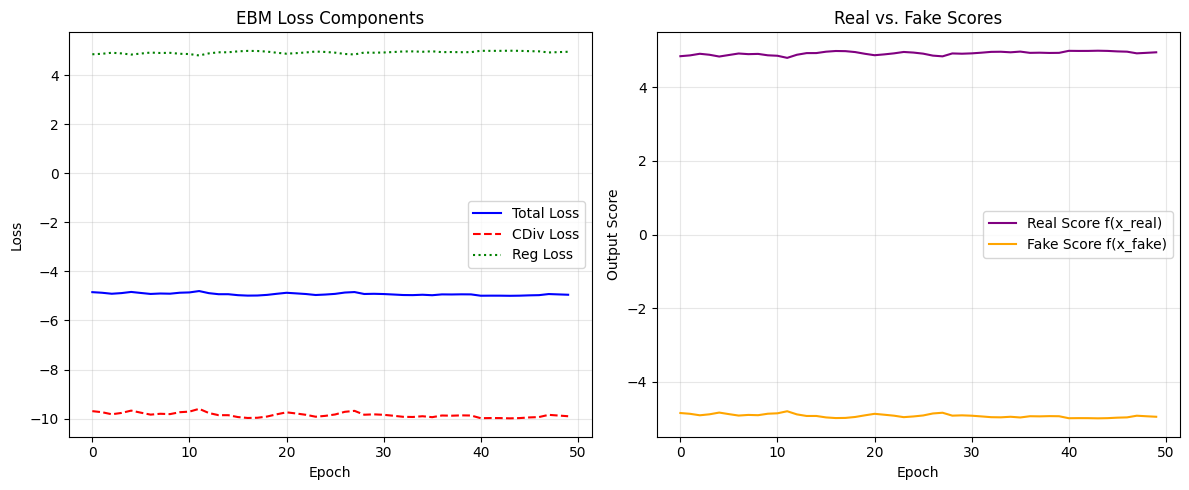

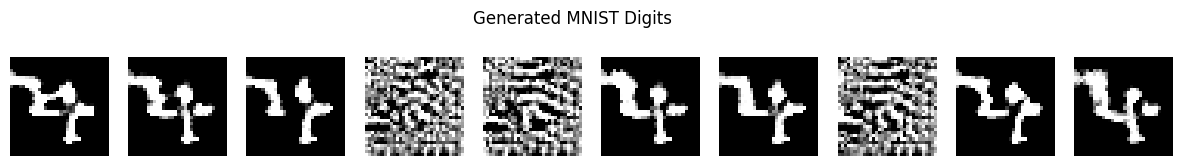

In [14]:
import matplotlib.pyplot as plt

# 1. Plot Loss Curves & Scores from your completed run
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_part2.history["loss"], label="Total Loss", color="blue")
plt.plot(history_part2.history["cdiv"], label="CDiv Loss", color="red", linestyle="--")
plt.plot(history_part2.history["reg"], label="Reg Loss", color="green", linestyle=":")
plt.title("EBM Loss Components")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_part2.history["real"], label="Real Score f(x_real)", color="purple")
plt.plot(history_part2.history["fake"], label="Fake Score f(x_fake)", color="orange")
plt.title("Real vs. Fake Scores")
plt.xlabel("Epoch")
plt.ylabel("Output Score")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("mnist_ebm_loss_curves.png", dpi=300)
plt.show()

# 2. Generate and Display 10 Handwritten Digits from Pure Noise
start_imgs = tf.random.uniform(shape=(10, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
gen_imgs = generate_samples(ebm.model, start_imgs, steps=1000, step_size=STEP_SIZE, noise=NOISE)

plt.figure(figsize=(15, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(gen_imgs[i].numpy().squeeze(), cmap="gray")
    plt.axis("off")
plt.suptitle("Generated MNIST Digits")
plt.savefig("generated_mnist_digits.png", dpi=300)
plt.show()